# GABUNGAN: SVM BASELINE & SVM PSO

Notebook ini berisi penggabungan dari dua tahapan:
1. **Metode SVM + TF-IDF Baseline**
2. **Metode SVM + PSO (Optimasi)**

---
# ==========================================
# BAGIAN 1: METODE SVM BASELINE
# ==========================================

# Klasifikasi Sentimen Ulasan DANA — SVM + TF-IDF (Metode Dasar / Baseline)

**Metode Dasar:**
- *Natural Language Processing (NLP)* untuk klasifikasi sentimen teks.
- *Support Vector Machine (SVM)* berbasis fitur **TF-IDF**.
- Menggunakan **parameter default** dari `scikit-learn` (tanpa optimasi).

**Dataset:** `Scraping/dana_reviews_semua.csv` (ulasan aplikasi DANA, label `Negatif` / `Positif`).

> File ini hanya berisi metode dasar. Untuk optimasi hyperparameter dengan PSO,
> lihat notebook `SVM_PSO_Optimasi.ipynb`.


## 1. Import Library

In [1]:
import re
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Library berhasil diimpor.")


Library berhasil diimpor.


## 2. Load Dataset

In [2]:
df = pd.read_csv('Scraping/dana_reviews_semua.csv')
print("Jumlah baris :", len(df))
print("Kolom       :", list(df.columns))
print("\nDistribusi sentimen:")
print(df['sentimen'].value_counts())
df.head(3)


Jumlah baris : 1000
Kolom       : ['rating', 'review', 'sentimen']

Distribusi sentimen:
sentimen
Negatif    500
Positif    500
Name: count, dtype: int64


,rating,review,sentimen
0,2,"abis di transfer dana 150k dari bapak, terus d...",Negatif
1,2,ko punya saya tida ada dana cicil yah,Negatif
2,2,saldo sering hilang di ambil tiktok coins rech...,Negatif


## 3. Text Preprocessing

Lowercase, hapus karakter non-alfabet, normalisasi spasi.
(Stemming/stopword sengaja tidak dilakukan agar kata sentimen penting
seperti "jelek", "buruk", "mantap" tetap terjaga.)


In [3]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['review_clean'] = df['review'].apply(clean_text)
label_map = {'Negatif': 0, 'Positif': 1}
df['label'] = df['sentimen'].map(label_map)
print(df[['review', 'review_clean', 'sentimen', 'label']].head(3))


                                              review  \
0  abis di transfer dana 150k dari bapak, terus d...   
1              ko punya saya tida ada dana cicil yah   
2  saldo sering hilang di ambil tiktok coins rech...   

                                        review_clean sentimen  label  
0  abis di transfer dana k dari bapak terus digun...  Negatif      0  
1              ko punya saya tida ada dana cicil yah  Negatif      0  
2  saldo sering hilang di ambil tiktok coins rech...  Negatif      0  


## 4. TF-IDF Vectorization & Train-Test Split

Teks diubah menjadi fitur numerik dengan **TF-IDF** (unigram + bigram).
Data dibagi 80% latih / 20% uji dengan stratifikasi.


In [4]:
texts = df['review_clean'].values
y = df['label'].values

# Split dilakukan sebelum TF-IDF di-fit agar data uji tidak bocor ke pelatihan.
texts_train, texts_test, y_train, y_test = train_test_split(
    texts, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train = vectorizer.fit_transform(texts_train)
X_test = vectorizer.transform(texts_test)

print("Dimensi TF-IDF data latih/uji :", X_train.shape, "/", X_test.shape)
print("Jumlah fitur                   :", len(vectorizer.vocabulary_))
print("Data latih / uji                :", X_train.shape[0], "/", X_test.shape[0])


Dimensi TF-IDF data latih/uji : (800, 1318) / (200, 1318)
Jumlah fitur                   : 1318
Data latih / uji                : 800 / 200


## 5. Model SVM dengan Parameter Default (Baseline)

`scikit-learn` default: `C=1.0`, `kernel='rbf'`, `gamma='scale'`.


In [5]:
svm_baseline = SVC(random_state=RANDOM_STATE)
svm_baseline.fit(X_train, y_train)
y_pred = svm_baseline.predict(X_test)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)

print("=== HASIL BASELINE SVM (parameter default) ===")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Negatif', 'Positif']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


=== HASIL BASELINE SVM (parameter default) ===
Accuracy  : 0.8200
Precision : 0.9000
Recall    : 0.7200
F1-Score  : 0.8000

Classification Report:
              precision    recall  f1-score   support

     Negatif       0.77      0.92      0.84       100
     Positif       0.90      0.72      0.80       100

    accuracy                           0.82       200
   macro avg       0.83      0.82      0.82       200
weighted avg       0.83      0.82      0.82       200

Confusion Matrix:
[[92  8]
 [28 72]]


## 6. Kesimpulan (Metode Dasar)

Model baseline SVM + TF-IDF dengan parameter default memberikan performa awal
sebagai tolok ukur. Notebook terpisah `SVM_PSO_Optimasi.ipynb` akan mengoptimasi
hyperparameter (`C`, `gamma`, `kernel`) menggunakan PSO untuk perbandingan.


## 7. Pengujian dengan 1 Data Baru

In [6]:
# Pengujian dengan 1 data baru (Baseline)
sample_text = "Aplikasi dana ini sangat memudahkan transaksi sehari-hari, sangat bagus!"

# Preprocessing (berdasarkan fungsi clean_text yang ada)
cleaned_sample = clean_text(sample_text)

# Ubah teks ke dalam bentuk TF-IDF menggunakan vectorizer yang sudah dilatih
sample_tfidf = vectorizer.transform([cleaned_sample])

# Prediksi menggunakan model SVM baseline
prediction = svm_baseline.predict(sample_tfidf)

label_map = {0: 'Negatif', 1: 'Positif'}
print("Teks Asli:", sample_text)
print("Teks Bersih:", cleaned_sample)
print("Hasil Prediksi (Baseline):", label_map.get(prediction[0], prediction[0]))

Teks Asli: Aplikasi dana ini sangat memudahkan transaksi sehari-hari, sangat bagus!
Teks Bersih: aplikasi dana ini sangat memudahkan transaksi sehari hari sangat bagus
Hasil Prediksi (Baseline): Positif


---
# ==========================================
# BAGIAN 2: METODE SVM PSO (OPTIMASI)
# ==========================================

# Analisis Sentimen DANA: SVM TF-IDF dan PSO

Notebook ini menggunakan pipeline bebas *data leakage*: pemisahan data dilakukan sebelum pelatihan TF-IDF, dan TF-IDF berada di dalam `Pipeline` saat validasi silang PSO.

In [7]:
import re
import numpy as np
import pandas as pd
import pyswarms as ps

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Library berhasil diimpor. PySwarms:', ps.__version__)

Library berhasil diimpor. PySwarms: 1.3.0


## Langkah 1 — Memuat dan memeriksa data

Dataset dibaca dari hasil scraping. Pemeriksaan jumlah data dan distribusi sentimen dilakukan untuk memastikan data berhasil dimuat serta kelas positif dan negatif tersedia.

In [8]:
df = pd.read_csv('Scraping/dana_reviews_semua.csv')
print('Jumlah data:', len(df))
print('\nDistribusi kelas:')
print(df['sentimen'].value_counts())
df.head()

Jumlah data: 1000

Distribusi kelas:
sentimen
Negatif    500
Positif    500
Name: count, dtype: int64


,rating,review,sentimen
0,2,"abis di transfer dana 150k dari bapak, terus d...",Negatif
1,2,ko punya saya tida ada dana cicil yah,Negatif
2,2,saldo sering hilang di ambil tiktok coins rech...,Negatif
3,2,saya mendapatkan limited dacil 150 stelah bela...,Negatif
4,1,tolol,Negatif


## Langkah 2 — Prapemrosesan dan pemisahan data

Teks diubah menjadi huruf kecil, karakter selain huruf dihapus, dan spasi dirapikan. Label Negatif dipetakan menjadi 0, sedangkan Positif menjadi 1. Data kemudian dibagi 80:20 secara stratified. `stratify=y` menjaga komposisi kelas pada data latih dan data uji tetap seimbang.

Pemisahan dilakukan **sebelum** TF-IDF. Data uji harus benar-benar tersembunyi dari proses pelatihan dan pencarian parameter.

In [9]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

x = df['review'].map(clean_text)
y = df['sentimen'].map({'Negatif': 0, 'Positif': 1})

# Split dilakukan sebelum vectorizer dilatih.
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print('Data latih:', len(x_train), '| Data uji:', len(x_test))

Data latih: 800 | Data uji: 200


## Langkah 3 — Membangun SVM baseline

Baseline menggunakan `SVC` dengan parameter default scikit-learn. `TfidfVectorizer` dan SVM digabungkan dalam `Pipeline`. Saat `fit`, TF-IDF hanya mempelajari kosakata serta bobot kata dari data latih. Model baseline menjadi pembanding yang adil bagi model hasil optimasi PSO.

In [10]:
def evaluate(model, x_train, y_train, x_test, y_test):
    model.fit(x_train, y_train)
    prediction = model.predict(x_test)
    return {
        'accuracy': accuracy_score(y_test, prediction),
        'precision': precision_score(y_test, prediction),
        'recall': recall_score(y_test, prediction),
        'f1': f1_score(y_test, prediction),
        'confusion_matrix': confusion_matrix(y_test, prediction),
        'report': classification_report(y_test, prediction, target_names=['Negatif', 'Positif'])
    }

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
    ('svm', SVC(random_state=RANDOM_STATE))
])
baseline_result = evaluate(baseline, x_train, y_train, x_test, y_test)
print('=== SVM BASELINE (bebas leakage) ===')
print(baseline_result['report'])
print('Confusion matrix:\n', baseline_result['confusion_matrix'])

=== SVM BASELINE (bebas leakage) ===
              precision    recall  f1-score   support

     Negatif       0.77      0.92      0.84       100
     Positif       0.90      0.72      0.80       100

    accuracy                           0.82       200
   macro avg       0.83      0.82      0.82       200
weighted avg       0.83      0.82      0.82       200

Confusion matrix:
 [[92  8]
 [28 72]]


## Langkah 4 — Menentukan fungsi objektif PSO

Setiap partikel menyatakan kombinasi `[log10(C), log10(gamma), indeks kernel]`. PSO memilih salah satu kernel `linear`, `rbf`, atau `poly`. Fungsi objektif yang diminimalkan ialah `1 - rata-rata accuracy validasi silang`.

`StratifiedKFold` dipakai agar setiap fold mempunyai proporsi label positif dan negatif yang sebanding. Pipeline dibuat ulang di setiap fold, sehingga TF-IDF tidak mempelajari teks dari fold validasi.

In [11]:
KERNELS = ['linear', 'rbf', 'poly']

def decode_position(position):
    c_value = 10 ** float(position[0])
    gamma_value = 10 ** float(position[1])
    kernel = KERNELS[int(np.clip(round(float(position[2])), 0, 2))]
    return c_value, gamma_value, kernel

# StratifiedKFold menjaga proporsi positif-negatif pada setiap fold.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def objective_function(particles):
    costs = []
    for particle in particles:
        c_value, gamma_value, kernel = decode_position(particle)
        candidate = Pipeline([
            ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
            ('svm', SVC(C=c_value, gamma=gamma_value, kernel=kernel, random_state=RANDOM_STATE))
        ])
        cv_accuracy = cross_val_score(
            candidate, x_train, y_train, cv=cv, scoring='accuracy', n_jobs=1
        ).mean()
        costs.append(1 - cv_accuracy)
    return np.array(costs)

## Langkah 5 — Menjalankan PSO

PSO menggunakan 10 partikel selama 20 iterasi. Nilai yang dicari adalah `C` pada rentang 0,1–100 dan `gamma` pada rentang 0,0001–1. Parameter dengan nilai objektif paling kecil (accuracy validasi silang terbesar) dipilih sebagai parameter optimal.

In [12]:
bounds = (np.array([-1.0, -4.0, 0.0]), np.array([2.0, 0.0, 2.0]))
optimizer = ps.single.GlobalBestPSO(
    n_particles=10, dimensions=3,
    options={'c1': 0.5, 'c2': 0.3, 'w': 0.9}, bounds=bounds
)

best_cost, best_position = optimizer.optimize(objective_function, iters=20)
best_c, best_gamma, best_kernel = decode_position(best_position)
print(f'CV accuracy terbaik: {1 - best_cost:.4f}')
print(f'C={best_c:.4f}, gamma={best_gamma:.6f}, kernel={best_kernel}')

2026-07-24 20:04:57,672 - pyswarms.single.global_best - INFO - Optimize for 20 iters with {'c1': 0.5, 'c2': 0.3, 'w': 0.9}
pyswarms.single.global_best: 100%|██████████|20/20, best_cost=0.203
2026-07-24 20:05:39,697 - pyswarms.single.global_best - INFO - Optimization finished | best cost: 0.2025334872762431, best pos: [ 0.89072731 -1.43271286  0.55695685]


CV accuracy terbaik: 0.7975
C=7.7755, gamma=0.036922, kernel=rbf


## Langkah 6 — Evaluasi akhir dan perbandingan

SVM dengan parameter terbaik dilatih ulang menggunakan seluruh data latih, lalu dievaluasi **sekali** pada data uji. Accuracy, precision, recall, dan F1-score dibandingkan dengan baseline. Nilai peningkatan positif berarti metrik model hasil PSO lebih baik daripada baseline.

In [13]:
optimized = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
    ('svm', SVC(C=best_c, gamma=best_gamma, kernel=best_kernel, random_state=RANDOM_STATE))
])
optimized_result = evaluate(optimized, x_train, y_train, x_test, y_test)

comparison = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'SVM Baseline': [baseline_result['accuracy'], baseline_result['precision'], baseline_result['recall'], baseline_result['f1']],
    'SVM + PSO': [optimized_result['accuracy'], optimized_result['precision'], optimized_result['recall'], optimized_result['f1']]
})
comparison['Peningkatan'] = comparison['SVM + PSO'] - comparison['SVM Baseline']
print('=== HASIL SVM + PSO ===')
print(optimized_result['report'])
print('Confusion matrix:\n', optimized_result['confusion_matrix'])
comparison

=== HASIL SVM + PSO ===
              precision    recall  f1-score   support

     Negatif       0.79      0.91      0.85       100
     Positif       0.89      0.76      0.82       100

    accuracy                           0.83       200
   macro avg       0.84      0.83      0.83       200
weighted avg       0.84      0.83      0.83       200

Confusion matrix:
 [[91  9]
 [24 76]]


,Metrik,SVM Baseline,SVM + PSO,Peningkatan
0,Accuracy,0.82,0.835000,0.015000
1,Precision,0.90,0.894118,-0.005882
2,Recall,0.72,0.760000,0.040000
3,F1-Score,0.80,0.821622,0.021622


## Catatan pelaporan

Gunakan tabel pada sel terakhir sebagai hasil final laporan. Jangan memakai nilai dari notebook lama karena TF-IDF sebelumnya di-fit sebelum pemisahan data.

## Langkah 7 — Visualisasi Perbandingan

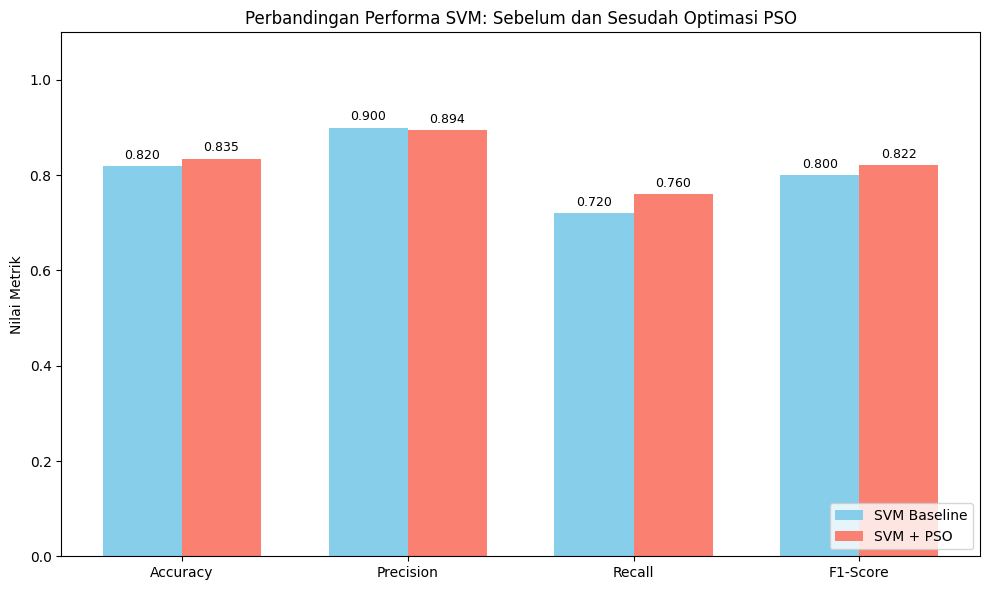

In [14]:
import matplotlib.pyplot as plt

# 1. Visualisasi perbandingan metrik evaluasi
x = np.arange(len(comparison['Metrik']))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, comparison['SVM Baseline'], width, label='SVM Baseline', color='skyblue')
rects2 = ax.bar(x + width/2, comparison['SVM + PSO'], width, label='SVM + PSO', color='salmon')

ax.set_ylabel('Nilai Metrik')
ax.set_title('Perbandingan Performa SVM: Sebelum dan Sesudah Optimasi PSO')
ax.set_xticks(x)
ax.set_xticklabels(comparison['Metrik'])
ax.set_ylim(0, 1.1)
ax.legend(loc='lower right')

# Menambahkan label nilai pada tiap bar
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()

## Langkah 8 — Pengujian dengan 1 Data Baru

In [15]:
# 2. Pengujian dengan 1 data baru (SVM + PSO)
sample_text = "Aplikasi dana ini sangat memudahkan transaksi sehari-hari, sangat bagus!"

# Preprocessing
cleaned_sample = clean_text(sample_text)

# Prediksi menggunakan pipeline SVM + PSO
prediction = optimized.predict([cleaned_sample])

label_map = {0: 'Negatif', 1: 'Positif'}
print("Teks Asli:", sample_text)
print("Teks Bersih:", cleaned_sample)
print("Hasil Prediksi (SVM + PSO):", label_map.get(prediction[0], prediction[0]))

Teks Asli: Aplikasi dana ini sangat memudahkan transaksi sehari-hari, sangat bagus!
Teks Bersih: aplikasi dana ini sangat memudahkan transaksi sehari hari sangat bagus
Hasil Prediksi (SVM + PSO): Positif


## Langkah 8a — Membuat Sampel untuk Validasi Manual

Sebelum penilaian manual dilakukan, program mengambil 100 sampel acak dari `df` (50 Negatif + 50 Positif) dengan `random_state=42` agar hasil sampling dapat direproduksi. File hasil sampling ini kemudian **diisi manual** oleh peneliti pada kolom `sentimen_manual` (penilaian isi teks) dan `sesuai_label_rating` (apakah label rating cocok dengan isi teks), lalu disimpan sebagai `validasi_manual_sampel.csv` dan dibaca kembali pada Langkah 9.

In [16]:
# Ambil 50 sampel Negatif dan 50 sampel Positif secara acak (reproducible)
sampel_negatif = df[df['sentimen'] == 'Negatif'].sample(n=50, random_state=42)
sampel_positif = df[df['sentimen'] == 'Positif'].sample(n=50, random_state=42)

sampel_validasi = pd.concat([sampel_negatif, sampel_positif])
sampel_validasi = sampel_validasi.reset_index().rename(columns={'index': 'indeks_data'})
sampel_validasi = sampel_validasi[['indeks_data', 'rating', 'review', 'sentimen']]

# Kolom ini dikosongkan dulu, lalu diisi MANUAL oleh peneliti setelah membaca teksnya
sampel_validasi['sentimen_manual'] = ''
sampel_validasi['sesuai_label_rating'] = ''

sampel_validasi.to_csv('sampel_untuk_validasi_manual.csv', index=False)
print(f"Sampel tersimpan: {len(sampel_validasi)} baris "
      f"({(sampel_validasi['sentimen']=='Negatif').sum()} Negatif, "
      f"{(sampel_validasi['sentimen']=='Positif').sum()} Positif)")
print("Selanjutnya: isi kolom 'sentimen_manual' dan 'sesuai_label_rating' secara manual,")
print("simpan sebagai 'validasi_manual_sampel.csv', lalu lanjut ke Langkah 9.")

Sampel tersimpan: 100 baris (50 Negatif, 50 Positif)
Selanjutnya: isi kolom 'sentimen_manual' dan 'sesuai_label_rating' secara manual,
simpan sebagai 'validasi_manual_sampel.csv', lalu lanjut ke Langkah 9.


## Langkah 9 — Validasi Manual Label (Sampel 100 Data)

Label sentimen pada dataset merupakan proxy dari rating (1-2 = Negatif, 4-5 = Positif), yang tidak selalu identik dengan isi teks ulasan. Untuk memeriksa hal ini, diambil sampel acak 100 ulasan (50 Negatif + 50 Positif, `random_state=42`) dan isi setiap ulasan dibandingkan secara manual dengan label berbasis rating. Hasil pemeriksaan disimpan pada `validasi_manual_sampel.csv`.

In [18]:
validasi = pd.read_csv('sampel_untuk_validasi_manual.csv')

n = len(validasi)
neg = validasi[validasi['sentimen'] == 'Negatif']
pos = validasi[validasi['sentimen'] == 'Positif']
neg_sesuai = int(neg['sesuai_label_rating'].sum())
pos_sesuai = int(pos['sesuai_label_rating'].sum())
total_sesuai = int(validasi['sesuai_label_rating'].sum())

print(f"Jumlah sampel divalidasi     : {n}")
print(f"  - Negatif                  : {len(neg)} (sesuai: {neg_sesuai}/{len(neg)})")
print(f"  - Positif                  : {len(pos)} (sesuai: {pos_sesuai}/{len(pos)})")
print(f"Total label sesuai           : {total_sesuai}/{n} ({total_sesuai/n:.1%})")
print(f"Total label tidak sesuai     : {n-total_sesuai}/{n} ({(n-total_sesuai)/n:.1%})")
print()
print("Contoh ulasan dengan label TIDAK sesuai:")
print(validasi[validasi['sesuai_label_rating'] == False][['rating', 'review', 'sentimen']].head(5).to_string(index=False))

Jumlah sampel divalidasi     : 100
  - Negatif                  : 50 (sesuai: 47/50)
  - Positif                  : 50 (sesuai: 41/50)
Total label sesuai           : 88/100 (88.0%)
Total label tidak sesuai     : 12/100 (12.0%)

Contoh ulasan dengan label TIDAK sesuai:
 rating                                                                                                                                                                                                                                review sentimen
      2                                                                                                                                                                                                                                    ok  Negatif
      2                                                                                                                                                                                                                                    ok

## Langkah 10 — Statistik Panjang Ulasan per Kelas

Menghitung rata-rata panjang karakter ulasan (sebelum prapemrosesan) untuk masing-masing kelas sentimen, menggunakan seluruh 1.000 data pada `df`.

In [19]:
panjang_karakter = df['review'].astype(str).str.len()
rata_rata_panjang = panjang_karakter.groupby(df['sentimen']).mean()

print("Rata-rata panjang ulasan (karakter) per kelas:")
print(rata_rata_panjang.round(1))

Rata-rata panjang ulasan (karakter) per kelas:
sentimen
Negatif    88.7
Positif    33.8
Name: review, dtype: float64
